# Notebook 04d: Random Forest Regressor
**Algorithm:** Random Forest (Bagging Ensemble)
**Core Strategy:** Decision Trees are highly resistant to outliers and do not require linear feature scaling. However, they are incredibly prone to **overfitting**. We will use `GridSearchCV` to constrain the trees and test both the 150-feature and 214-feature datasets to see which one provides the best signal-to-noise ratio.


## 1. Imports & Data Loading


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import joblib
sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')
DATA_DIR = "../../data/final_for_modeling/"
# Load 150-Feature Dataset (Selected by Random Forest)
X_train_150 = pd.read_csv(f"{DATA_DIR}X_train_full.csv").fillna(0)
X_test_150 = pd.read_csv(f"{DATA_DIR}X_test_full.csv").fillna(0)
# Load 214-Feature Dataset (No Selection)
X_train_214 = pd.read_csv("../../data/processed/X_train_scaled.csv").fillna(0)
X_test_214 = pd.read_csv("../../data/processed/X_test_scaled.csv").fillna(0)
y_train = pd.read_csv(f"{DATA_DIR}y_train.csv").squeeze()
y_test = pd.read_csv(f"{DATA_DIR}y_test.csv").squeeze()
print(f"Loaded 150-feature dataset: {X_train_150.shape}")
print(f"Loaded 214-feature dataset: {X_train_214.shape}")


Loaded 150-feature dataset: (958, 150)
Loaded 214-feature dataset: (958, 203)


## 2. Dataset Showdown: Baseline RF (150 vs 214 Features)


In [10]:
# Train on 150 features
rf_base_150 = RandomForestRegressor(random_state=42)
rf_base_150.fit(X_train_150, y_train)
y_pred_150 = rf_base_150.predict(X_test_150)
mae_150 = mean_absolute_error(y_test, y_pred_150)
# Train on 214 features
rf_base_214 = RandomForestRegressor(random_state=42)
rf_base_214.fit(X_train_214, y_train)
y_pred_214 = rf_base_214.predict(X_test_214)
mae_214 = mean_absolute_error(y_test, y_pred_214)
# Calculate full metrics for the winning 150-feature baseline
y_train_pred_base = rf_base_150.predict(X_train_150)
train_mae_base = mean_absolute_error(y_train, y_train_pred_base)
train_rmse_base = mean_squared_error(y_train, y_train_pred_base) ** 0.5
test_rmse_base = mean_squared_error(y_test, y_pred_150) ** 0.5
train_r2_base = r2_score(y_train, y_train_pred_base)
test_r2_base = r2_score(y_test, y_pred_150)
within_10_base = (abs(y_test - y_pred_150) / y_test <= 0.10).mean() * 100
print("=== BASELINE (UNTUNED) RANDOM FOREST METRICS ===")
print(f"{'Metric':<25} {'Train':>15} {'Test':>15}")
print('-' * 55)
print(f"{'R² Score':<25} {train_r2_base:>15.4f} {test_r2_base:>15.4f}")
print(f"{'RMSE ($)':<25} {train_rmse_base:>15,.2f} {test_rmse_base:>15,.2f}")
print(f"{'MAE ($)':<25} {train_mae_base:>15,.2f} {mae_150:>15,.2f}")
print('-' * 55)
print(f"Predictions within 10%: {within_10_base:.1f}%\n")
print(f"214-Feature Baseline MAE was: ${mae_214:,.2f} (Discarded)")


=== BASELINE (UNTUNED) RANDOM FOREST METRICS ===
Metric                              Train            Test
-------------------------------------------------------
R² Score                           0.9850          0.8801
RMSE ($)                         8,692.41       22,278.50
MAE ($)                          5,705.58       14,798.30
-------------------------------------------------------
Predictions within 10%: 71.7%

214-Feature Baseline MAE was: $14,881.26 (Discarded)


### Visualizing the Baseline (Untuned) Model
Before we tune the model, let's look at the raw, untuned predictions to see what flaws (like overfitting or heteroscedasticity) we need the GridSearch to fix.

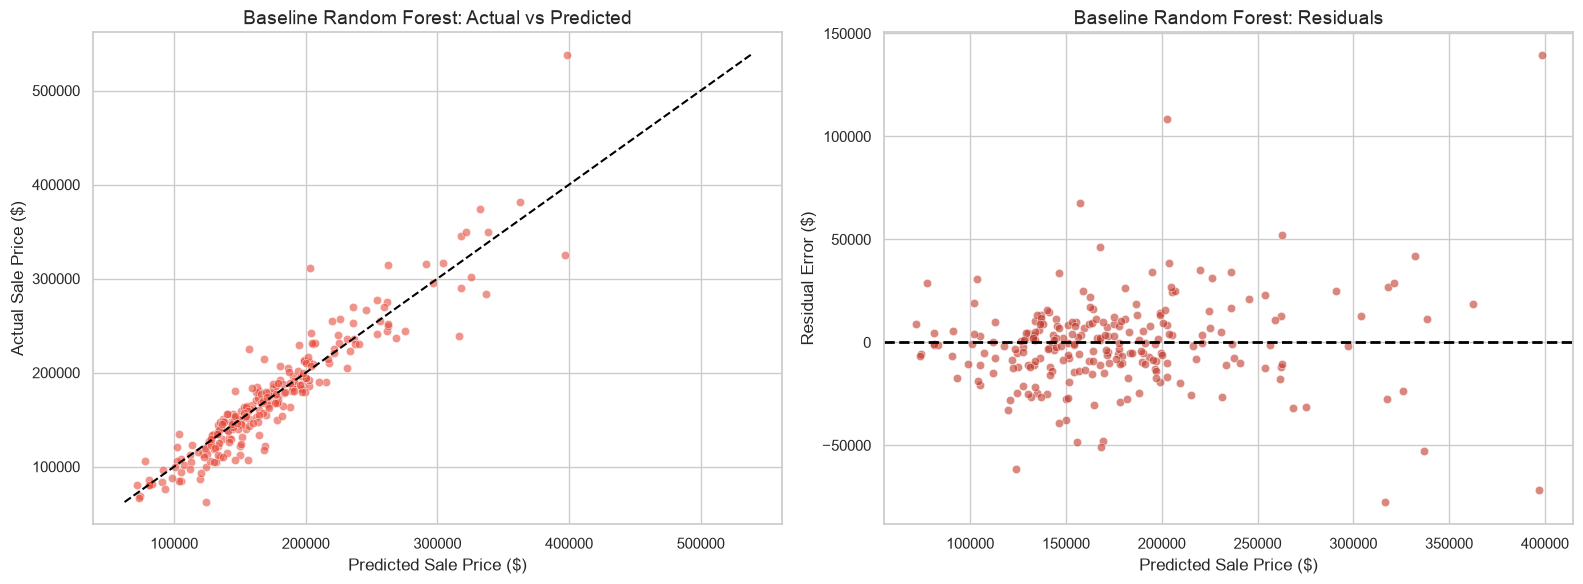

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Actual vs Predicted (Baseline)
sns.scatterplot(x=y_pred_150, y=y_test, alpha=0.6, color="#e74c3c", ax=axes[0])
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="black", linestyle="--")
axes[0].set_title('Baseline Random Forest: Actual vs Predicted', fontsize=14)
axes[0].set_xlabel('Predicted Sale Price ($)')
axes[0].set_ylabel('Actual Sale Price ($)')

# Plot 2: Residuals (Baseline)
residuals_base = y_test - y_pred_150
sns.scatterplot(x=y_pred_150, y=residuals_base, alpha=0.6, color="#c0392b", ax=axes[1])
axes[1].axhline(y=0, color="black", linestyle="--", lw=2)
axes[1].set_title('Baseline Random Forest: Residuals', fontsize=14)
axes[1].set_xlabel('Predicted Sale Price ($)')
axes[1].set_ylabel('Residual Error ($)')

plt.tight_layout()
plt.show()


## 3. Hyperparameter Tuning (GridSearch)


> **Note:** Random Forests naturally overfit (Train R² often hits 0.98). We use `max_depth`, `min_samples_split`, and `max_features` to constrain the trees and force them to generalize.


In [12]:
# Assuming 150 features wins the baseline, we tune on it. (If 214 wins, you can swap the variables here)
X_train_tune = X_train_150
X_test_tune = X_test_150

param_grid = {
    'n_estimators': [100, 300, 500],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'max_features': ['sqrt', 'log2', 1.0] # 1.0 means use all features (Bagging), sqrt is true Random Forest
}

print("Starting GridSearch... (This may take 1-3 minutes)")
grid_search = GridSearchCV(RandomForestRegressor(random_state=42), param_grid, cv=3, scoring='neg_mean_absolute_error', n_jobs=-1, verbose=1)
grid_search.fit(X_train_tune, y_train)

best_rf = grid_search.best_estimator_
print(f"\nOptimal Hyperparameters: {grid_search.best_params_}")


Starting GridSearch... (This may take 1-3 minutes)
Fitting 3 folds for each of 108 candidates, totalling 324 fits

Optimal Hyperparameters: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 300}


## 4. Evaluate Tuned Model (Diagnosing Overfitting)


In [13]:
y_train_pred = best_rf.predict(X_train_tune)
y_test_pred = best_rf.predict(X_test_tune)

train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)
train_rmse = mean_squared_error(y_train, y_train_pred) ** 0.5
test_rmse = mean_squared_error(y_test, y_test_pred) ** 0.5
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

within_10 = (abs(y_test - y_test_pred) / y_test <= 0.10).mean() * 100

print("=== TUNED RANDOM FOREST METRICS ===")
print(f"{'Metric':<25} {'Train':>15} {'Test':>15}")
print('-' * 55)
print(f"{'R² Score':<25} {train_r2:>15.4f} {test_r2:>15.4f}")
print(f"{'RMSE ($)':<25} {train_rmse:>15,.2f} {test_rmse:>15,.2f}")
print(f"{'MAE ($)':<25} {train_mae:>15,.2f} {test_mae:>15,.2f}")
print('-' * 55)
print(f"Predictions within 10%: {within_10:.1f}%")


=== TUNED RANDOM FOREST METRICS ===
Metric                              Train            Test
-------------------------------------------------------
R² Score                           0.9847          0.8896
RMSE ($)                         8,769.06       21,375.70
MAE ($)                          5,425.32       13,571.90
-------------------------------------------------------
Predictions within 10%: 72.9%


## 5. Diagnostic Plots


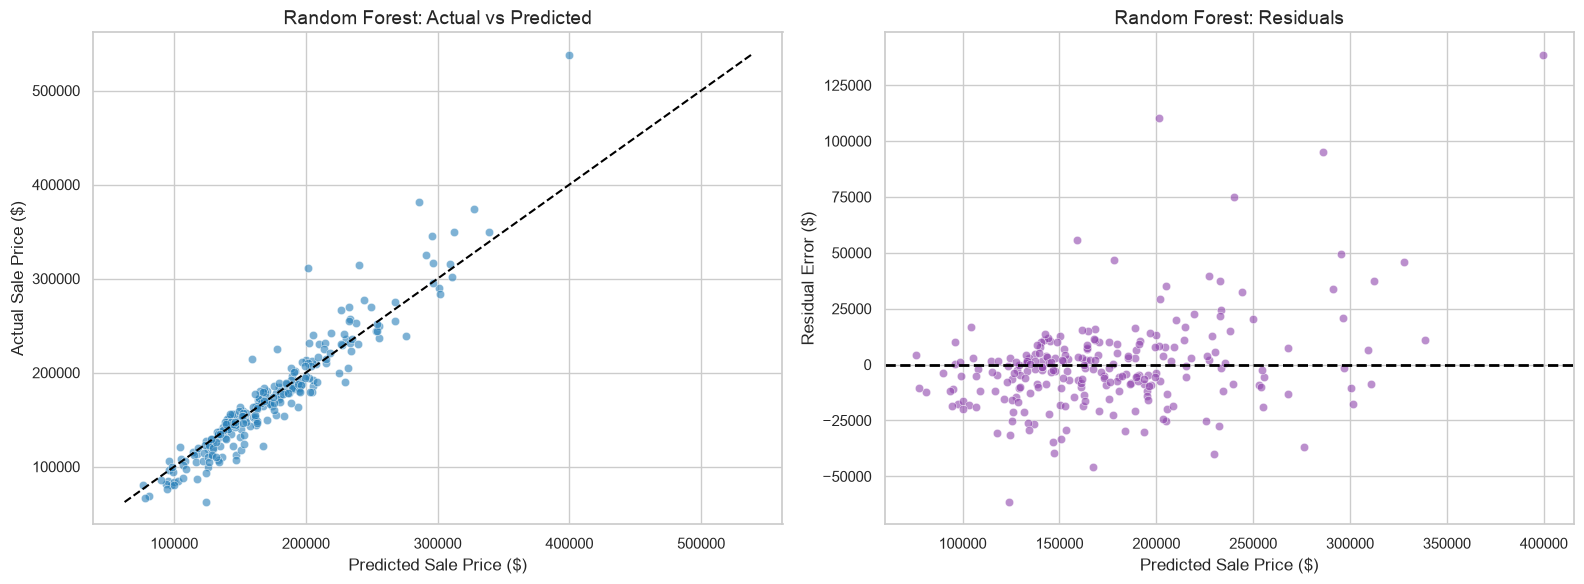

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Actual vs Predicted
sns.scatterplot(x=y_test_pred, y=y_test, alpha=0.6, color="#2980b9", ax=axes[0])
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="black", linestyle="--")
axes[0].set_title('Random Forest: Actual vs Predicted', fontsize=14)
axes[0].set_xlabel('Predicted Sale Price ($)')
axes[0].set_ylabel('Actual Sale Price ($)')

# Plot 2: Residuals
residuals = y_test - y_test_pred
sns.scatterplot(x=y_test_pred, y=residuals, alpha=0.6, color="#8e44ad", ax=axes[1])
axes[1].axhline(y=0, color="black", linestyle="--", lw=2)
axes[1].set_title('Random Forest: Residuals', fontsize=14)
axes[1].set_xlabel('Predicted Sale Price ($)')
axes[1].set_ylabel('Residual Error ($)')

plt.tight_layout()
plt.show()


## 6. Feature Importance (The Power of Trees)


> **Why this is awesome:** Unlike SVR or Ridge, Random Forest can natively tell us exactly which features it used to make its decisions!


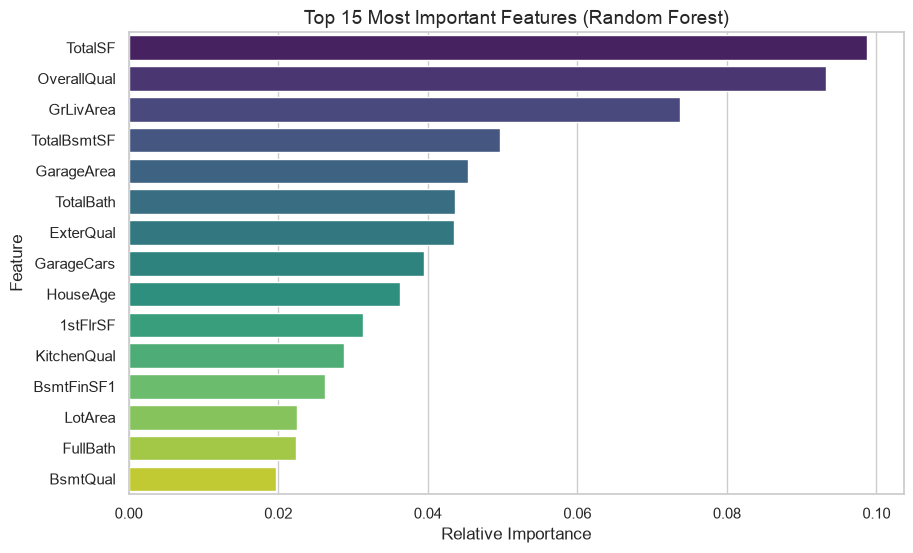

In [15]:
importances = best_rf.feature_importances_
feature_names = X_train_tune.columns

# Create a DataFrame and sort
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
importance_df = importance_df.sort_values(by='Importance', ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='viridis')
plt.title('Top 15 Most Important Features (Random Forest)', fontsize=14)
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.show()


## 7. Save Final Model


In [16]:
os_path = '../../models/random_forest_tuned.pkl'
joblib.dump(best_rf, os_path)
print(f"Random Forest model successfully saved to: {os_path}")


Random Forest model successfully saved to: ../../models/random_forest_tuned.pkl
